# Frozen-model evaluation

Evaluate the selected XGBoost model and **threshold 0.62**. Model settings,
probabilities and contact rule remain frozen: no fitting, calibration training,
threshold search or model selection. Test has already been evaluated; these are
additional descriptive diagnostics, not a fresh independent model-selection stage.
All rates and costs refer to customer-week instances unless stated otherwise.

**Evaluation population:** all metrics, curves and confusion matrices below use
**104,034 customer snapshots from the final test set**, covering Monday cutoffs
**June 6–October 17, 2011**, and **5,558 distinct customers**. One observation is
one `(Customer ID, cutoff)` pair: the same customer may appear in multiple weeks.
The outcome is whether that customer purchases in the 50 days after that cutoff.
Weekly and history-group sections are slices of this same test population; they
are not training or policy-holdout results. The model and threshold were selected
before this evaluation using development data.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from online_retail.modeling.evaluation import (
    load_evaluation, summarize, grouped_metrics, plot_overall, plot_weekly, plot_groups,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data/processed"
ARTIFACT = ROOT / "artifacts/final_roc_policy"
OUTPUT = ROOT / "artifacts/evaluation"
OUTPUT.mkdir(parents=True, exist_ok=True)

## 1. Verify the frozen experiment

Match saved predictions to test features one-to-one on customer/cutoff, verify
outcomes and reproduce probabilities from the trusted local pipeline. Confirm
saved contact decisions match the frozen threshold. Reconstruct the actual final
fitting population from metadata to identify previously unseen customer IDs.
Do not use the full exploratory customer table: history groups use each snapshot's
past-only invoice count.

In [2]:
evaluation, frozen = load_evaluation(DATA, ARTIFACT)
threshold, costs = frozen["threshold"], frozen["costs"]
assert frozen["model"] == "xgboost" and threshold == 0.62
pd.Series({"model": frozen["model"], "threshold": threshold,
    "test_snapshots": len(evaluation), "distinct_customers": evaluation["Customer ID"].nunique(),
    "first_cutoff": evaluation.cutoff.min(), "last_cutoff": evaluation.cutoff.max(),
    "fit_last_cutoff": frozen["fit_last_cutoff"]})

model                             xgboost
threshold                            0.62
test_snapshots                     104034
distinct_customers                   5558
first_cutoff          2011-06-06 00:00:00
last_cutoff           2011-10-17 00:00:00
fit_last_cutoff       2011-01-10 00:00:00
dtype: object

## 2. Overall evaluation

ROC-AUC and average precision summarize ranking. Log loss and Brier score assess
probability quality; no classification cutoff enters those metrics. Precision,
recall, F1 and confusion counts use only the frozen 0.62 threshold. The PR reference
line shows purchase prevalence. The reliability plot compares predicted and observed
purchase fractions in ten quantile bins: it does not fit a recalibration model.

In [3]:
overall = pd.Series(summarize(evaluation, threshold, costs), name="test")
overall.to_csv(OUTPUT / "overall.csv")
overall.round(4)

snapshots                 104034.0000
customers                   5558.0000
buyers                     28186.0000
nonbuyers                  75848.0000
purchase_rate                  0.2709
mean_probability               0.4025
roc_auc                        0.7948
average_precision              0.6504
log_loss                       0.5098
brier_score                    0.1673
accuracy                       0.7962
precision                      0.7077
recall                         0.4224
f1                             0.5291
contact_rate                   0.1617
contacts                   16826.0000
mean_cost                      5.7657
total_cost                599830.0000
contact_none_mean_cost         6.7733
contact_all_mean_cost         13.6453
tn                         70929.0000
fp                          4919.0000
fn                         16279.0000
tp                         11907.0000
Name: test, dtype: float64

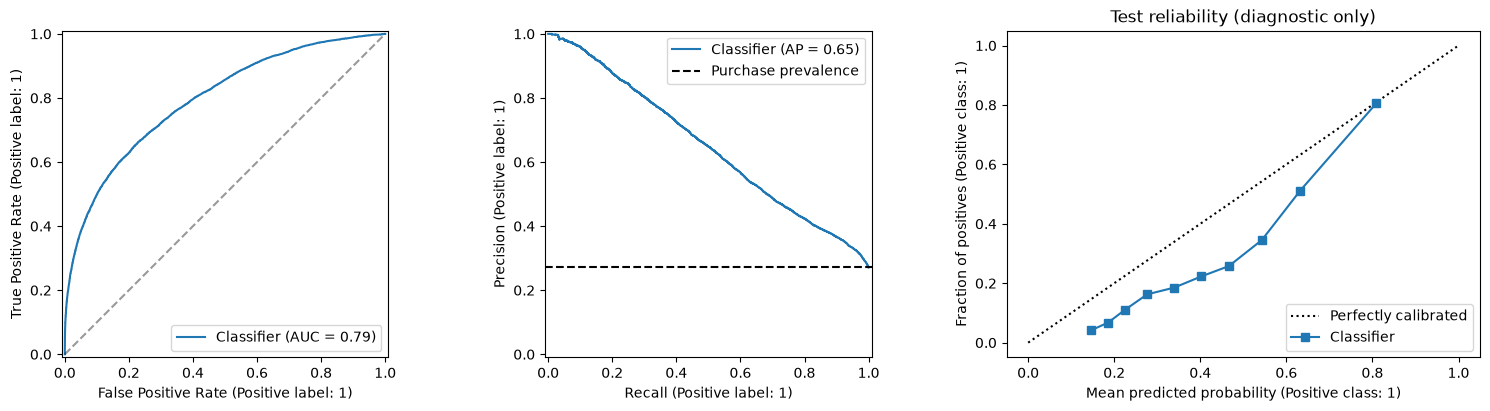

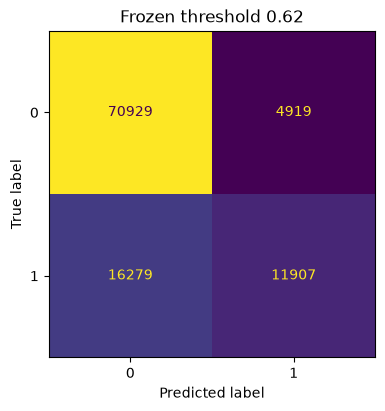

In [4]:
ranking_figure, confusion_figure = plot_overall(evaluation, threshold)
plt.show()

**Interpretation.** At threshold 0.62, approximately 70.8% of contacted instances
purchase, while the policy reaches approximately 42.2% of buyers. ROC-AUC is about
0.795. High precision does not establish incremental marketing benefit.

The saved costs are illustrative: TN £0, FP £15, FN £25, TP £10. Costs include
assumed penalties and are not measured campaign spending or profit.

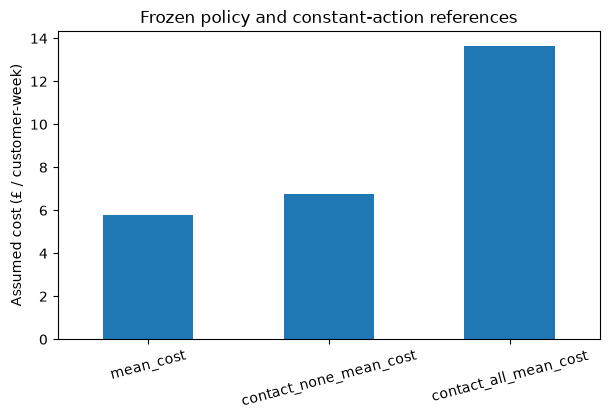

In [5]:
overall[["mean_cost", "contact_none_mean_cost", "contact_all_mean_cost"]].plot.bar(
    figsize=(7, 4), rot=15, ylabel="Assumed cost (£ / customer-week)",
    title="Frozen policy and constant-action references")
plt.show()

## 3. Performance by scoring week

Keep the same model and threshold every week. Changes in outcome prevalence can
move precision and average precision even when ranking stays similar. Compare
mean predicted probability with observed purchase rate to describe probability bias.
Counts show how much data supports each week. Customer histories and 50-day labels
overlap across weeks: points are correlated, not independent experimental results.
No confidence intervals or significance claims assume independent rows.

In [6]:
weekly = grouped_metrics(evaluation, "cutoff", threshold, costs)
weekly.to_csv(OUTPUT / "weekly_metrics.csv")
weekly[["snapshots", "buyers", "purchase_rate", "roc_auc", "average_precision",
        "precision", "recall", "contact_rate", "mean_cost"]].round(4)

,snapshots,buyers,purchase_rate,roc_auc,average_precision,precision,recall,contact_rate,mean_cost
cutoff,,,,,,,,,
2011-06-06,4951,1237,0.2498,0.8037,0.6497,0.7331,0.4042,0.1377,5.2828
2011-06-13,4977,1187,0.2385,0.8041,0.6402,0.7104,0.4153,0.1394,5.0824
2011-06-20,5005,1165,0.2328,0.8036,0.6350,0.6938,0.4163,0.1397,5.0070
2011-06-27,5030,1152,0.2290,0.8033,0.6356,0.6887,0.4245,0.1412,4.9264
2011-07-04,5049,1169,0.2315,0.8062,0.6375,0.7013,0.4098,0.1353,4.9713
2011-07-11,5065,1150,0.2270,0.8159,0.6427,0.7111,0.4174,0.1333,4.8322
2011-07-18,5088,1155,0.2270,0.8187,0.6503,0.7239,0.4199,0.1317,4.7907
2011-07-25,5116,1175,0.2297,0.8105,0.6405,0.7128,0.4162,0.1341,4.8857
2011-08-01,5143,1208,0.2349,0.8145,0.6482,0.7208,0.4338,0.1414,4.9358


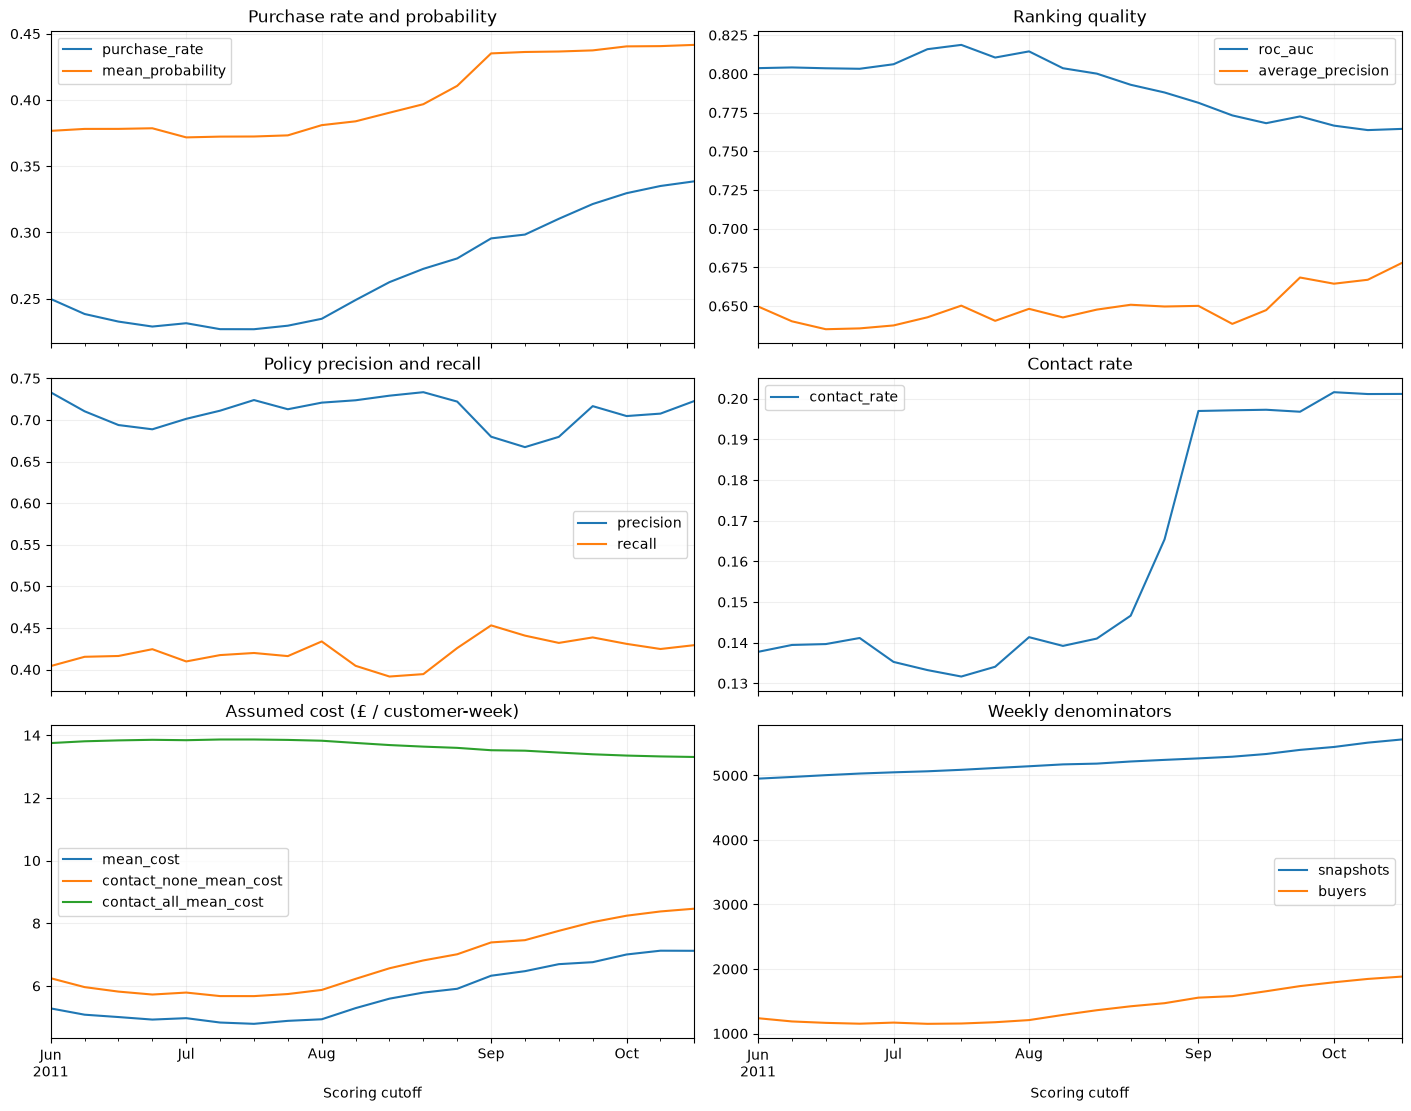

In [7]:
plot_weekly(weekly)
plt.show()

## 4. Performance by customer history

History groups use strictly past invoice counts **at each scoring cutoff**:
one invoice, 2–3 invoices, and 4+ invoices. Customers may change groups over time.
Distinct-customer counts across groups therefore need not add up to the global
count. These are observed purchases, not true lifetime customer tenure.

Identity groups ask whether an ID occurred among the rows used to fit this exact
final model. An unseen ID still has observed transaction history at scoring time.
The final-fit membership definition differs from membership in initial training.

Inspect denominators and prevalence before comparing metrics. ROC-AUC is missing
when a group has only one outcome; precision is missing with no predicted buyers,
and recall/AP are missing with no actual buyers. Undefined F1 uses zero. These
are descriptive slices, not a basis for fitting group-specific thresholds on test.

In [8]:
group_columns = ["snapshots", "customers", "buyers", "nonbuyers", "purchase_rate",
    "roc_auc", "average_precision", "log_loss", "brier_score", "precision", "recall",
    "f1", "contact_rate", "mean_cost", "contact_none_mean_cost", "contact_all_mean_cost"]
history = grouped_metrics(evaluation, "history_group", threshold, costs)
identity = grouped_metrics(evaluation, "identity_group", threshold, costs)
history.to_csv(OUTPUT / "history_metrics.csv")
identity.to_csv(OUTPUT / "identity_metrics.csv")
history[group_columns].round(4)

,snapshots,customers,buyers,nonbuyers,purchase_rate,roc_auc,average_precision,log_loss,brier_score,precision,recall,f1,contact_rate,mean_cost,contact_none_mean_cost,contact_all_mean_cost
history_group,,,,,,,,,,,,,,,,
1 invoice,31661,2124,3233,28428,0.1021,0.7105,0.2387,0.3455,0.0956,NaN,0.0000,0.0000,0.0000,2.5528,2.5528,14.4894
2–3 invoices,28955,1877,5324,23631,0.1839,0.6510,0.3088,0.5177,0.1672,0.6528,0.0177,0.0344,0.0050,4.5740,4.5968,14.0806
4+ invoices,43418,2376,19629,23789,0.4521,0.7674,0.7582,0.6243,0.2196,0.7081,0.6018,0.6507,0.3842,8.9033,11.3023,12.7395


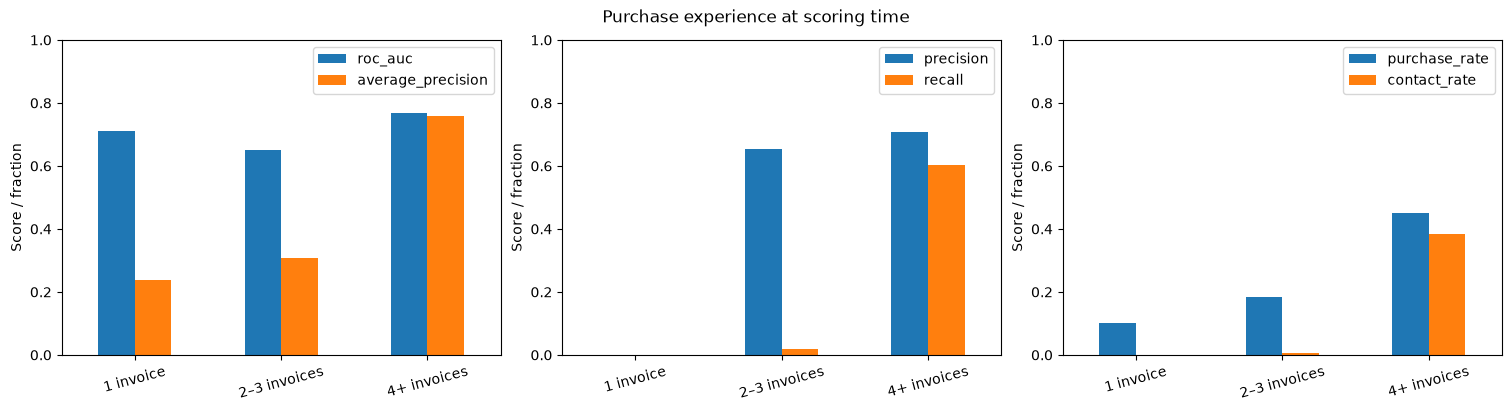

In [9]:
plot_groups(history, "Purchase experience at scoring time")
plt.show()

In [10]:
identity[group_columns].round(4)

,snapshots,customers,buyers,nonbuyers,purchase_rate,roc_auc,average_precision,log_loss,brier_score,precision,recall,f1,contact_rate,mean_cost,contact_none_mean_cost,contact_all_mean_cost
identity_group,,,,,,,,,,,,,,,,
Seen in final fit,87120,4356,23085,64035,0.2650,0.8213,0.6788,0.5044,0.1651,0.7051,0.4746,0.5673,0.1783,5.5270,6.6245,13.6751
Unseen in final fit,16914,1202,5101,11813,0.3016,0.7328,0.5682,0.5375,0.1787,0.7380,0.1866,0.2979,0.0763,6.9951,7.5396,13.4921


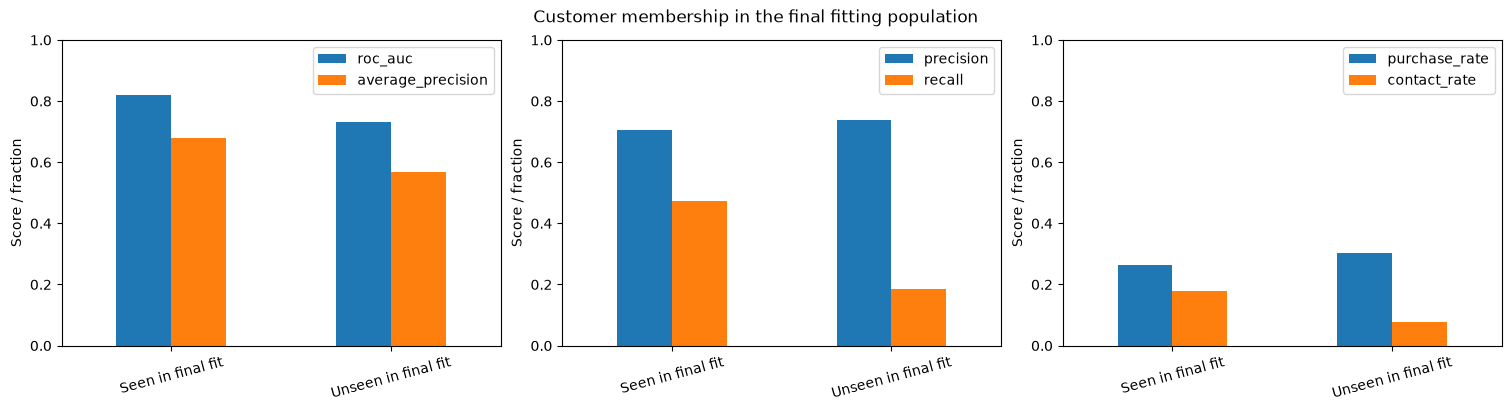

In [11]:
plot_groups(identity, "Customer membership in the final fitting population")
plt.show()

## Evaluation boundaries

Tables are saved under `artifacts/evaluation/`. This notebook never updates the
model or threshold and includes no controlled-campaign experiment. Observed segment
and weekly differences suggest questions for future data; changing a model in
response requires a new evaluation plan. Individual purchase propensity does not
identify the causal effect of advertising. See [modeling](../docs/modeling.md) and
[results](../docs/results.md) for the original frozen experiment.

## Main findings

- Weekly ROC-AUC ranges from **0.764 to 0.819**; precision ranges **0.667–0.733**
  and recall **0.392–0.453**. These ranges describe correlated weeks, not confidence
  intervals or proof of seasonal effects. Purchase prevalence also changes.
- The frozen policy contacts **no one-invoice snapshots**. Their recall is zero
  and precision is undefined, not zero. Only **1.8%** of buyers in the 2–3 invoice
  group are reached, versus **60.2%** among the 4+ invoice group. The global recall
  therefore conceals substantial differences in purchase-history coverage.
- Previously unseen customers have ROC-AUC **0.733**, versus **0.821** for seen
  customers. Buyer recall is **18.7%**, versus **47.5%**; purchase rates are **30.2%**
  and **26.5%**, respectively. Unseen IDs can be scored, but these results do not
  support assuming the same quality for them as for previously observed IDs.
- Group costs reflect different outcome prevalence as well as decisions. Lower cost
  in the one-invoice group does not establish better predictions: nobody is contacted
  there, and assumed loss consists entirely of missed-buyer penalties.

These findings characterize this frozen policy. We have not changed its threshold
or fitted group-specific rules from test outcomes. Further model improvements
would require development experiments and a new evaluation plan.